## 1. Introduction

### Breast Cancer Classification: PCA and Explainable Machine Learning

- Machine learning can help identify patterns in medical data, but accurate predictions are not the only goal. Understanding which features matter and whether models can work with fewer variables is also important.

- In this project, I use the `Breast Cancer Wisconsin Diagnostic dataset` to `classify tumors as malignant or benign based on measurements of cell nuclei.`

- The dataset contains `569 observations and 30 numerical features describing characteristics` such as radius, texture, perimeter, area, and concavity.
`
- I compare four classification models: `Logistic Regression, Support Vector Machine (SVM), K-Nearest Neighbors (KNN), and Random Forest`.

- I also use `Principal Component Analysis (PCA)` to explore the structure of the data and `SHAP` to better understand model predictions.

- The main goal is to investigate the relationship between model performance, feature reduction, and interpretability.

-  This is an educational data analysis project, not a medical diagnostic tool.

### Research Questions

This project focuses on four questions:

1. How well can Logistic Regression, SVM, KNN, and Random Forest classify malignant and benign tumors?
2. How much of the dataset's variance can be explained by a smaller number of principal components?
3. Can PCA reduce the number of input dimensions while maintaining similar classification performance?
4. Which original features contribute most to the model predictions, and how can SHAP help explain them?
---


## 2. Import Libraries

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted") 
plt.rcParams["figure.figsize"] = (8, 5)


from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    auc
)

import shap



## 3. Loading the Dataset

In [37]:
from sklearn.datasets import load_breast_cancer

# Load the Breast Cancer Wisconsin dataset
cancer = load_breast_cancer()

# Create feature matrix
X = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

# Set malignant as the positive class
# 0 = Benign, 1 = Malignant
y = pd.Series(
    (cancer.target == 0).astype(int),
    name="target"
)

# Create DataFrame for exploratory analysis
df = X.copy()
df["target"] = y

# Add readable class names for visualization
df["Diagnosis"] = df["target"].map({
    0: "Benign",
    1: "Malignant"
})

print("Dataset shape:", X.shape)
print("\nClass distribution:")
print(df["Diagnosis"].value_counts())



Dataset shape: (569, 30)

Class distribution:
Diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


---


## 4. Dataset Overview

In [8]:
# dataset description
print(cancer['DESCR'])

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

- The dataset contains 569 observations and 30 numerical features describing cell nuclei.
- The target has two classes: benign (0) and malignant (1). The features include measurements of size, shape, and texture.

In [38]:
# feature names
print(cancer['feature_names'])

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


---


## 5. Exploratory Data Analysis

Data Inspection & Descriptive Statistics:

In [10]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [11]:
print(X.shape)  

(569, 30)


The dataset has 569 samples and 30 features.



Target variable distribution:
Diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


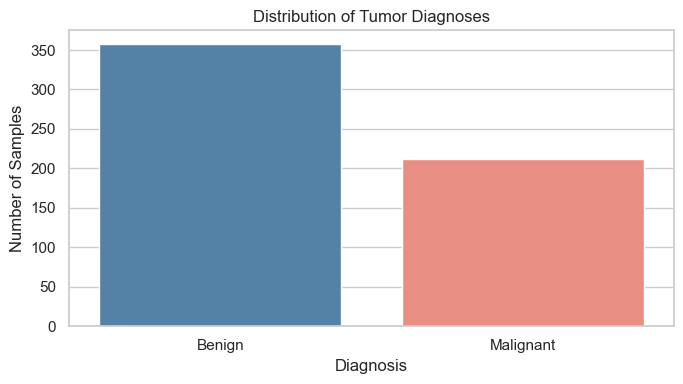

In [39]:

# Display the number of samples in each class
class_counts = df["Diagnosis"].value_counts()

print("Target variable distribution:")
print(class_counts)

# Visualize class distribution
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="Diagnosis",
    order=["Benign", "Malignant"],
    hue="Diagnosis",
    hue_order=["Benign", "Malignant"],
    palette={
        "Benign": "steelblue",
        "Malignant": "salmon"
    },
    legend=False
)

plt.title("Distribution of Tumor Diagnoses")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


- The dataset contains more benign tumors (357) than malignant tumors (212). This class difference should be considered when evaluating the models.

---

In [13]:
print("\nDataset information:")
X.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoo

- This shows the structure of the feature matrix (number of samples, number of features, and data types) for the breast cancer dataset.
- It helps confirm that all columns are numeric and there are no missing values before modeling.

In [14]:
X.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


- This summary shows basic statistics for each feature in the breast cancer dataset, including mean, standard deviation, and value ranges. 
- Most features (such as mean radius, mean perimeter, and mean area) have wide ranges, indicating significant variation in tumor size. 
- We will normalize these features before model training.


---


## 6. Data Cleaning

In [15]:
# Check for missing values
print(X.isnull().sum())

# Check for duplicates
print(f"Duplicate rows: {X.duplicated().sum()}")

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64
Duplicate rows: 0


- No missing values or duplicate rows were found.
- All 30 input features are numeric, so no additional data cleaning was needed for this analysis.

---




## 7. Feature Analysis and Visualizations

### 7.1 Correlation Matrix

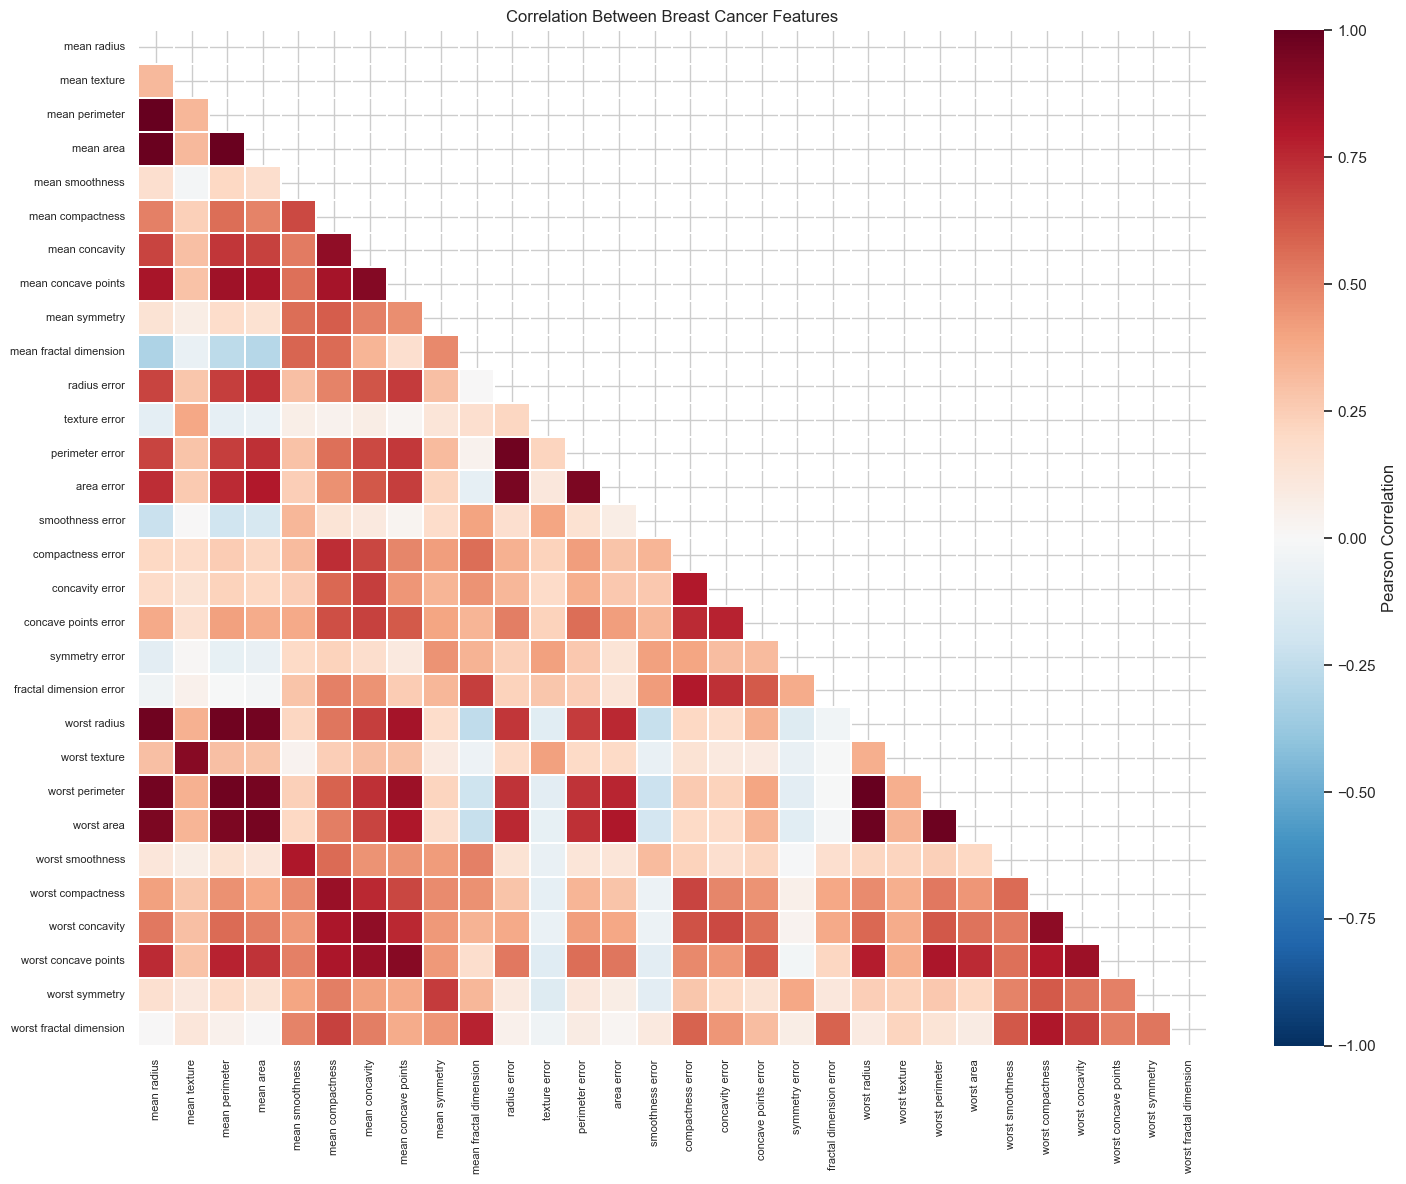

In [40]:
# Calculate correlations between the 30 features
correlation_matrix = X.corr()

# Hide the upper triangle to reduce clutter
mask = np.triu(
    np.ones_like(correlation_matrix, dtype=bool)
)

plt.figure(figsize=(15, 12))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False,
    linewidths=0.2,
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title("Correlation Between Breast Cancer Features")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()


### Correlation Heatmap Interpretation

- Several features are strongly correlated, especially measurements related to tumor size, such as radius, perimeter, and area.
- This suggests that some features contain overlapping information, which makes dimensionality reduction with PCA worth exploring.
---

### 7.2 KDE Plots (Distributions for Malignant vs Benign)

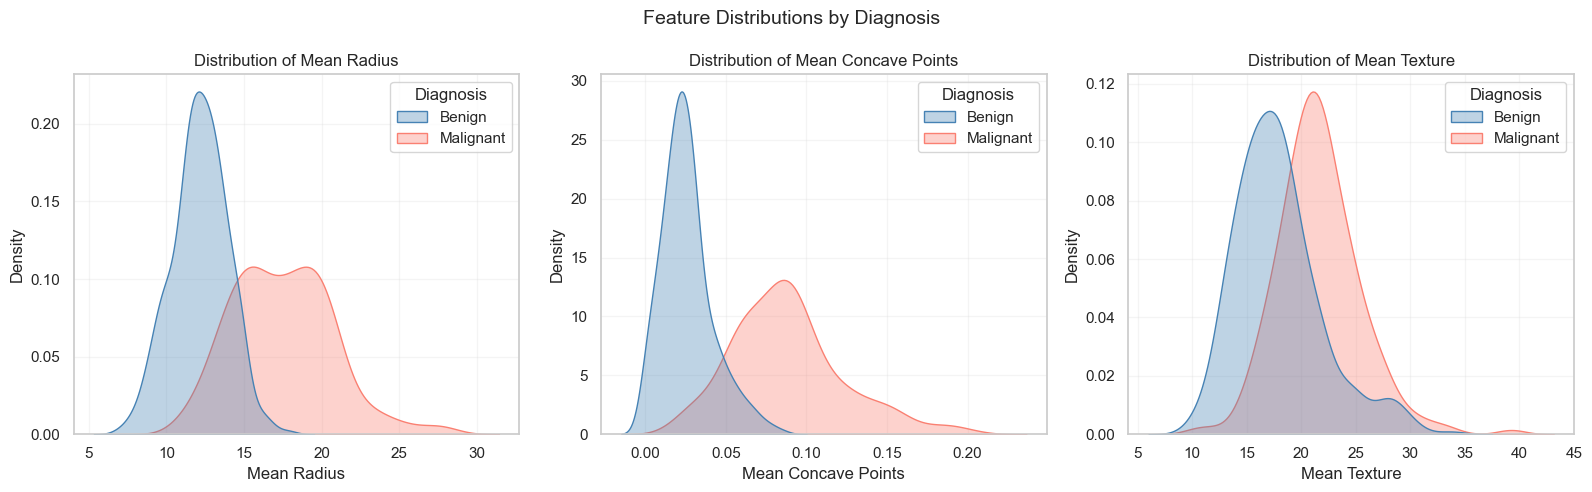

In [41]:

# Compare distributions of three different tumor features
features_to_plot = [
    "mean radius",
    "mean concave points",
    "mean texture"
]

# Consistent colors across visualizations
class_colors = {
    "Benign": "steelblue",
    "Malignant": "salmon"
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

for ax, feature in zip(axes, features_to_plot):

    sns.kdeplot(
        data=df,
        x=feature,
        hue="Diagnosis",
        hue_order=["Benign", "Malignant"],
        palette=class_colors,
        fill=True,
        alpha=0.35,
        common_norm=False,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature.title()}")
    ax.set_xlabel(feature.title())
    ax.set_ylabel("Density")
    ax.grid(alpha=0.2)

plt.suptitle(
    "Feature Distributions by Diagnosis",
    fontsize=14
)

plt.tight_layout()
plt.show()


### KDE Plot Interpretation

- Malignant tumors generally have higher values for mean radius and mean concave points.
- Mean texture also differs between the groups, but the distributions overlap more.
- These plots suggest that size and shape measurements may help distinguish the two classes.

---

### 7.3 Visualizing Class Differences with Scatter Plots

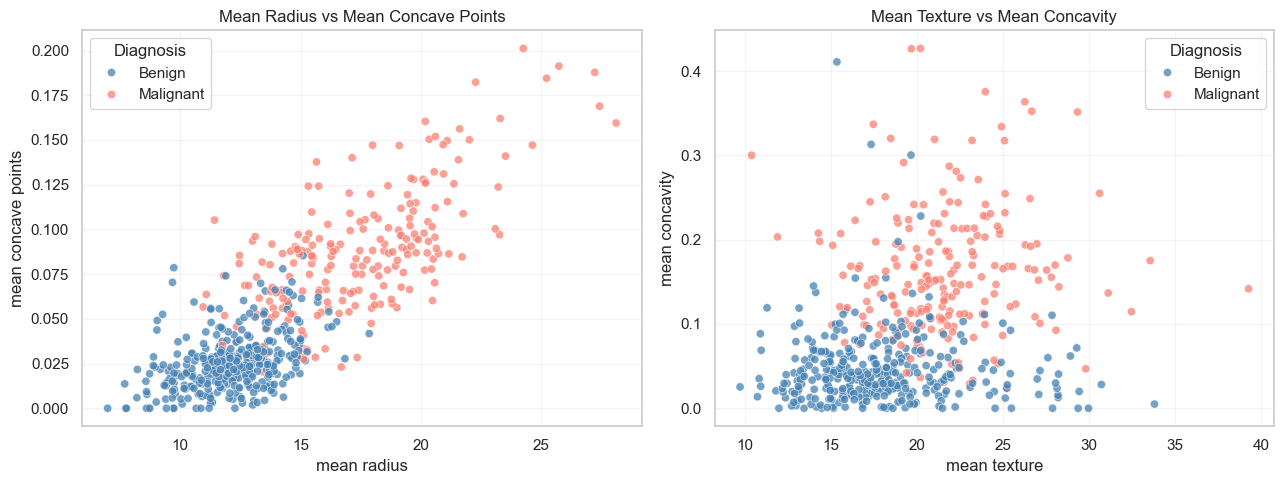

In [42]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Tumor size and shape
sns.scatterplot(
    data=df,
    x="mean radius",
    y="mean concave points",
    hue="Diagnosis",
    hue_order=["Benign", "Malignant"],
    palette=class_colors,
    alpha=0.75,
    ax=axes[0]
)

axes[0].set_title("Mean Radius vs Mean Concave Points")
axes[0].grid(alpha=0.2)

# Plot 2: Texture and shape
sns.scatterplot(
    data=df,
    x="mean texture",
    y="mean concavity",
    hue="Diagnosis",
    hue_order=["Benign", "Malignant"],
    palette=class_colors,
    alpha=0.75,
    ax=axes[1]
)

axes[1].set_title("Mean Texture vs Mean Concavity")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()


### Scatter Plot Interpretation

- Malignant tumors tend to have higher values for radius and concave points, although the classes overlap.
- The second plot also shows some separation based on texture and concavity, but neither pair of features can perfectly distinguish the two classes.

---

### 7.4 Box Plots for Outliers

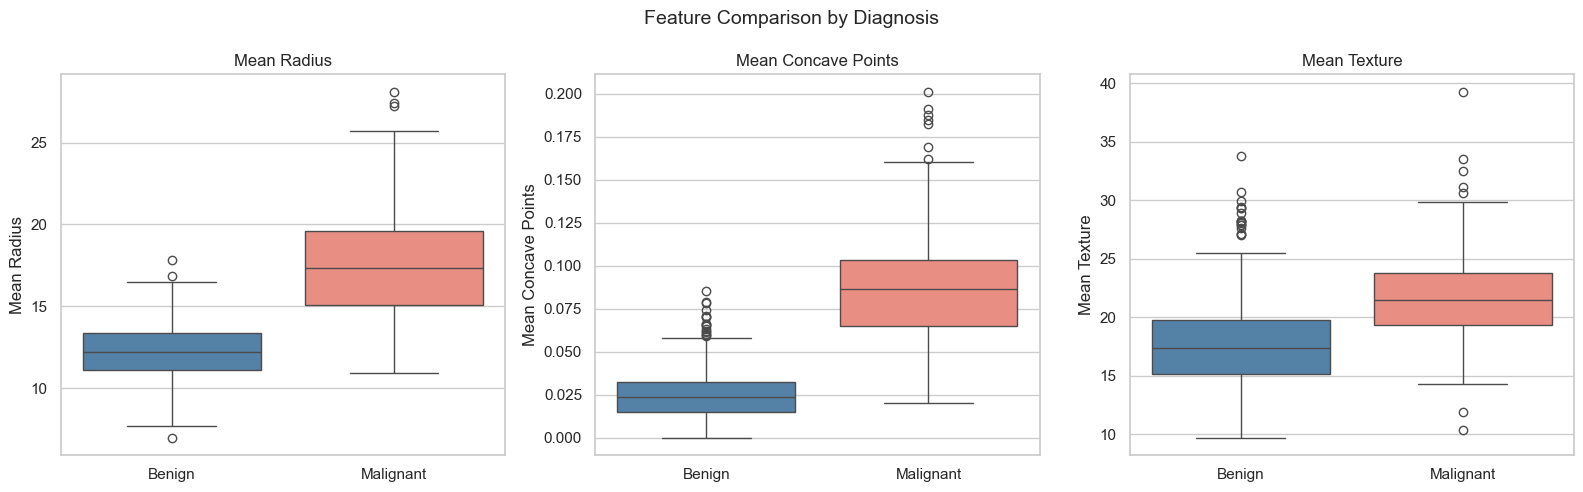

In [43]:

features_to_compare = [
    "mean radius",
    "mean concave points",
    "mean texture"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, features_to_compare):

    sns.boxplot(
        data=df,
        x="Diagnosis",
        y=feature,
        order=["Benign", "Malignant"],
        hue="Diagnosis",
        hue_order=["Benign", "Malignant"],
        palette=class_colors,
        legend=False,
        ax=ax
    )

    ax.set_title(feature.title())
    ax.set_xlabel("")
    ax.set_ylabel(feature.title())

plt.suptitle(
    "Feature Comparison by Diagnosis",
    fontsize=14
)

plt.tight_layout()
plt.show()


### Box Plot Interpretation

- Malignant tumors generally show higher median values for radius and concave points.
- Texture also differs between the groups, but the values overlap more.
- The box plots help compare the spread and median of each feature across the two diagnosis groups.

---


## 8. Split the data
### Split the data into training and test sets

In [45]:
# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.map({0: "Benign", 1: "Malignant"}).value_counts())

print("\nTest class distribution:")
print(y_test.map({0: "Benign", 1: "Malignant"}).value_counts())


Training set: (455, 30)
Test set: (114, 30)

Training class distribution:
target
Benign       285
Malignant    170
Name: count, dtype: int64

Test class distribution:
target
Benign       72
Malignant    42
Name: count, dtype: int64


### Train/Test Split

- I split the dataset into 80% training data and 20% test data.
- Stratification keeps the class proportions similar in both sets. The test data is kept separate from the PCA fitting and model training steps.

---

## 9. Scaling

In [46]:
# Fit the scaler using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the fitted scaler
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)


Scaled training shape: (455, 30)
Scaled test shape: (114, 30)


### Feature Scaling

- I used StandardScaler to put the features on a comparable scale.
- The scaler was fitted only on the training data and then applied to the test data. This prevents information from the test set from influencing preprocessing.

---

## 10. Principal Component Analysis (PCA)
### 10.1 PCA Projection

Explained variance by PC1: 0.446
Explained variance by PC2: 0.185
Total explained variance: 0.631


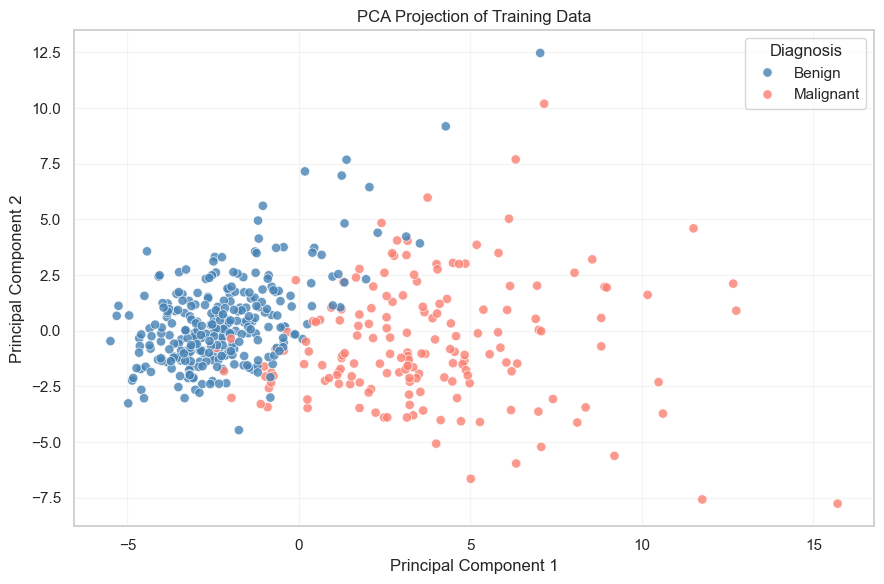

In [47]:

# Reduce the scaled training data to two components
pca_2d = PCA(n_components=2)

X_train_pca = pca_2d.fit_transform(X_train_scaled)

# Transform the test data with the same PCA
X_test_pca = pca_2d.transform(X_test_scaled)

print(
    "Explained variance by PC1:",
    round(pca_2d.explained_variance_ratio_[0], 3)
)

print(
    "Explained variance by PC2:",
    round(pca_2d.explained_variance_ratio_[1], 3)
)

print(
    "Total explained variance:",
    round(pca_2d.explained_variance_ratio_.sum(), 3)
)

# Create a DataFrame for plotting
pca_plot_df = pd.DataFrame({
    "PC1": X_train_pca[:, 0],
    "PC2": X_train_pca[:, 1],
    "Diagnosis": y_train.map({
        0: "Benign",
        1: "Malignant"
    }).to_numpy()
})

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_plot_df,
    x="PC1",
    y="PC2",
    hue="Diagnosis",
    hue_order=["Benign", "Malignant"],
    palette={
        "Benign": "steelblue",
        "Malignant": "salmon"
    },
    alpha=0.8,
    s=45
)

plt.title("PCA Projection of Training Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Diagnosis")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### PCA Projection Interpretation

- The first two principal components explain approximately 63% of the variation in the training data.
- The plot shows some separation between benign and malignant tumors, although the groups overlap.
- This suggests that PCA captures useful patterns, but two components do not fully separate the classes.

### 10.2  Explained Variance Analysis 

Components for 90% variance: 7
Components for 95% variance: 10


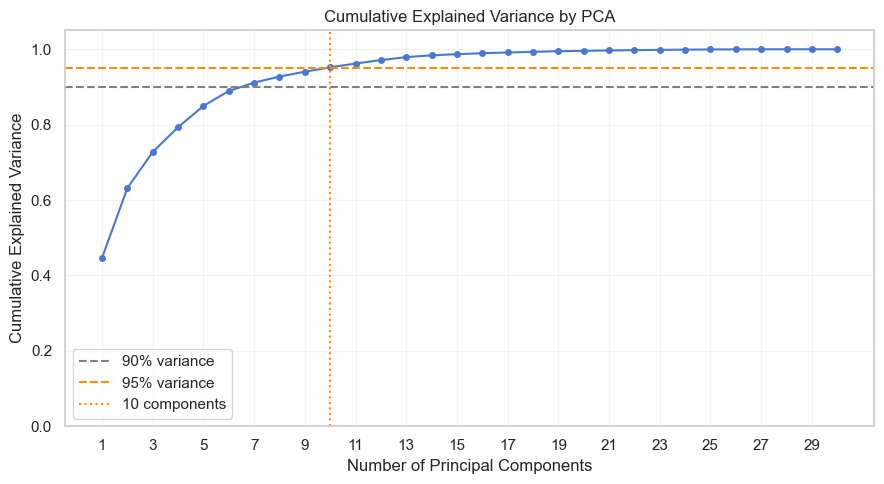

In [48]:
# Fit PCA with all components on scaled training data
pca_full = PCA()
pca_full.fit(X_train_scaled)

# Cumulative explained variance
cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

component_numbers = np.arange(
    1,
    len(cumulative_variance) + 1
)

# Number of components for 90% and 95% variance
n_components_90 = np.searchsorted(
    cumulative_variance, 0.90
) + 1

n_components_95 = np.searchsorted(
    cumulative_variance, 0.95
) + 1

print("Components for 90% variance:", n_components_90)
print("Components for 95% variance:", n_components_95)

# Plot cumulative explained variance
plt.figure(figsize=(9, 5))

plt.plot(
    component_numbers,
    cumulative_variance,
    marker="o",
    markersize=4
)

plt.axhline(
    y=0.90,
    color="gray",
    linestyle="--",
    label="90% variance"
)

plt.axhline(
    y=0.95,
    color="darkorange",
    linestyle="--",
    label="95% variance"
)

plt.axvline(
    x=n_components_95,
    color="darkorange",
    linestyle=":",
    label=f"{n_components_95} components"
)

plt.title("Cumulative Explained Variance by PCA")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.xticks(range(1, 31, 2))
plt.ylim(0, 1.05)
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()


### Explained Variance Analysis

- I used cumulative explained variance to examine how many principal components are needed to retain most of the variation in the training data.
- A smaller number of components may reduce the dimensionality of the dataset, but retaining a high percentage of variance does not automatically guarantee good classification performance.
- In the next step, I will compare models trained with the original features and PCA-transformed features.

---

## 11. Classification Models: Training and Prediction 

### 11.1 Training the Models

In [23]:
# Logistic Regression
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)

# SVM
svm_model = SVC(probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train)

# KNN
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

# Random Forest (no scaling needed)
rf_model = RandomForestClassifier(
    n_estimators=200,             # number of trees in the forest | use 200 trees for more stable predictions
    random_state=42
)
rf_model.fit(X_train, y_train);


- We train several models to compare different ways of separating the classes and see which one works best on this dataset.
- Each model looks at the data from a different angle, so this gives a fair and practical comparison.


- **Logistic Regression**: A simple linear model and a strong baseline

- **SVM**: Focuses on finding a clear boundary between classes. Works well when classes are not easily separable.

- **KNN**: Makes predictions based on the closest samples.

- **Random Forest**: Combines many decision trees to make predictions and it does not require feature scaling.

### 11.2 Making Predictions


In [24]:
# Generate predictions for the test set using the trained models
log_pred = log_model.predict(X_test_scaled)
svm_pred = svm_model.predict(X_test_scaled)
knn_pred = knn_model.predict(X_test_scaled)
rf_pred = rf_model.predict(X_test)

- In this step, we use the trained models to make predictions on the test data.

- The test set contains data the models have never seen before, so this helps us evaluate how well they generalize to new samples.

- Logistic Regression, SVM, and KNN use the scaled test data because they are sensitive to feature magnitude.

- Random Forest uses the original test data since tree-based models do not require scaling.

- The output of each model is a predicted class label for every sample in the test set. These predictions will later be compared with the true labels to measure model performance.
---


## 12. Evaluation


### 12.1 Classification reports
This code generates a classification report for each machine learning model and displays the results as tables.

In [25]:
# output_dict=True returns the metrics as a dictionary instead of plain text.
reports = {
    "Logistic Regression": classification_report(y_test, log_pred, output_dict=True),
    "SVM": classification_report(y_test, svm_pred, output_dict=True),
    "KNN": classification_report(y_test, knn_pred, output_dict=True),
    "Random Forest": classification_report(y_test, rf_pred, output_dict=True)
}

# Convert each report to a pandas DataFrame and display it as a table.
for name, report in reports.items():
    df = pd.DataFrame(report).transpose()
    print(f"\n{name}")
    display(df.round(3))
    
    


Logistic Regression


,precision,recall,f1-score,support
0,0.959,0.986,0.973,72.000
1,0.975,0.929,0.951,42.000
accuracy,0.965,0.965,0.965,0.965
macro avg,0.967,0.957,0.962,114.000
weighted avg,0.965,0.965,0.965,114.000



SVM


,precision,recall,f1-score,support
0,0.960,1.000,0.980,72.000
1,1.000,0.929,0.963,42.000
accuracy,0.974,0.974,0.974,0.974
macro avg,0.980,0.964,0.971,114.000
weighted avg,0.975,0.974,0.973,114.000



KNN


,precision,recall,f1-score,support
0,0.947,0.986,0.966,72.000
1,0.974,0.905,0.938,42.000
accuracy,0.956,0.956,0.956,0.956
macro avg,0.961,0.945,0.952,114.000
weighted avg,0.957,0.956,0.956,114.000



Random Forest


,precision,recall,f1-score,support
0,0.947,1.000,0.973,72.000
1,1.000,0.905,0.950,42.000
accuracy,0.965,0.965,0.965,0.965
macro avg,0.974,0.952,0.961,114.000
weighted avg,0.967,0.965,0.965,114.000


- Each report includes important evaluation metrics such as precision, recall, F1-score, and support for each class, as well as overall performance measures.
- By using output_dict=True, the classification report is returned as a dictionary instead of plain text. This allows the results to be easily converted into a pandas DataFrame and displayed in a cleaner tabular format.
- This makes it easier to compare how different models perform on the test set.
---

1. Precision
- Precision measures how many of the samples predicted as positive are actually positive.
Formula = True Positives / (True Positives + False Positives)
- A high precision means the model makes fewer false positive predictions.
- Precision is important when we want to avoid incorrectly labeling healthy people as diseased.

---

2. Recall
- Recall measures how many of the actual positive samples are correctly identified by the model.
- Formula = True Positives / (True Positives + False Negatives)
- A high recall means the model misses fewer real positive cases.
- Recall is often very important because missing a true patient can be more dangerous than making a false alarm.

---

3. F1-score
- F1-score is the harmonic mean of precision and recall.
- It gives a balanced measure of model performance when both false positives and false negatives matter.
- It is especially helpful when the dataset is imbalanced.

---

4. Support
- Support is the number of actual samples belonging to each class in the test set.
- It shows how many examples were used to calculate the metrics for each class.

---

5. Accuracy
- Accuracy measures the overall proportion of correct predictions.
- Formula = Correct Predictions / Total Predictions
- It gives a general summary of performance, but it may be misleading if the classes are imbalanced.

---

### 12.2 Comparison Table
- A summary table to compare the overall performance of all models :

In [26]:
summary_rows = []

for name, report in reports.items():
    summary_rows.append({
        "Model": name,
        "Accuracy": report["accuracy"],                               # Overall prediction accuracy
        "Precision (weighted)": report["weighted avg"]["precision"],  # Weighted precision across classes
        "Recall (weighted)": report["weighted avg"]["recall"],        # Weighted recall across classes
        "F1-score (weighted)": report["weighted avg"]["f1-score"]     # Balanced performance metric
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df.round(3))

,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
0,Logistic Regression,0.965,0.965,0.965,0.965
1,SVM,0.974,0.975,0.974,0.973
2,KNN,0.956,0.957,0.956,0.956
3,Random Forest,0.965,0.967,0.965,0.965


### Model comparison interpretation

- The table summarizes the overall performance of the four classification models in predicting breast cancer diagnosis based on accuracy, weighted precision, weighted recall, and weighted F1-score.

- Logistic Regression and SVM achieved the highest performance across all metrics, each obtaining a score of 0.982.
- This indicates that both models were highly effective in distinguishing between malignant and benign tumors.
- Their high weighted F1-scores also suggest a strong balance between precision and recall across the dataset.

- KNN and Random Forest achieved slightly lower scores of 0.956 across all evaluation metrics.
- Although these models still demonstrate strong classification ability, their performance indicates slightly weaker generalization compared to Logistic Regression and SVM.

Overall, Logistic Regression and SVM appear to be the most reliable models for this breast cancer classification task, showing superior accuracy and balanced predictive performance.

---

### 12.3 Confusion matrix
We will plot the confusion matrix for each model

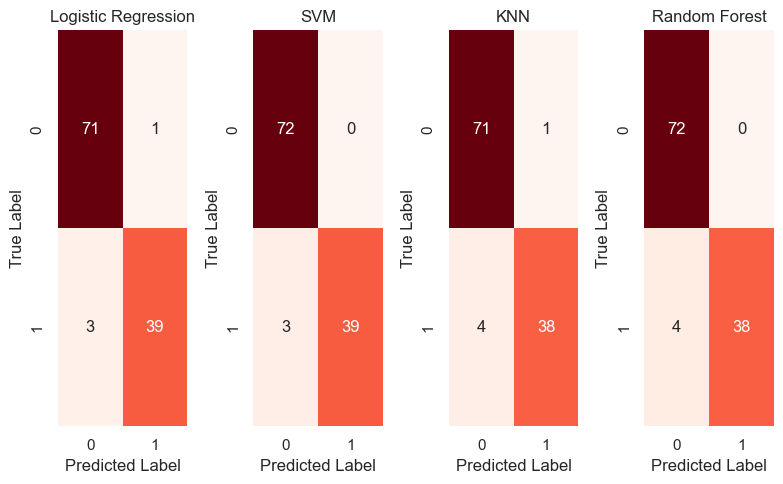

In [27]:
models_preds = [
    ("Logistic Regression", log_pred),   #Create a list of model names and their prediction
    ("SVM", svm_pred),
    ("KNN", knn_pred),
    ("Random Forest", rf_pred)
]

# Loop through each model and plot its confusion matrix
for i, (name, pred) in enumerate(models_preds, start=1):
    plt.subplot(1, 4, i)  # Create 4 plots in one row
    
    cm = confusion_matrix(y_test, pred)  # Compute confusion matrix
    
    # Plot confusion matrix as a heatmap
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Reds",
        cbar=False
        )
    
    plt.title(f"{name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

plt.tight_layout()
plt.show()


### Interpretation of the Confusion Matrices

- The confusion matrices show how each model classified benign and malignant tumors.

- Logistic Regression and SVM show almost perfect classification performance.

- They have very few false positives and false negatives, indicating strong reliability in detecting both malignant and benign tumors.

- KNN and Random Forest also perform well, but they show slightly more misclassifications compared to Logistic Regression and SVM.

### False Negatives 
- In medical diagnosis, false negatives are more dangerous than false positives.

- A false negative means a malignant tumor is classified as benign.

- Logistic Regression and SVM have the lowest number of false negatives, making them more suitable for medical screening tasks.

### False positives
- False positives mean predicting malignant when it is actually benign.

- While less critical than false negatives, too many false positives can cause unnecessary stress and additional medical tests.

- All models show relatively low false positives, but again Logistic Regression and SVM appear slightly more balanced.

- Although all four models perform strongly, Logistic Regression and SVM demonstrate the best balance between sensitivity and overall accuracy.

- This makes them the most reliable choices for breast cancer classification in this dataset.

---

### 12.4 ROC Analysis for Model Comparison


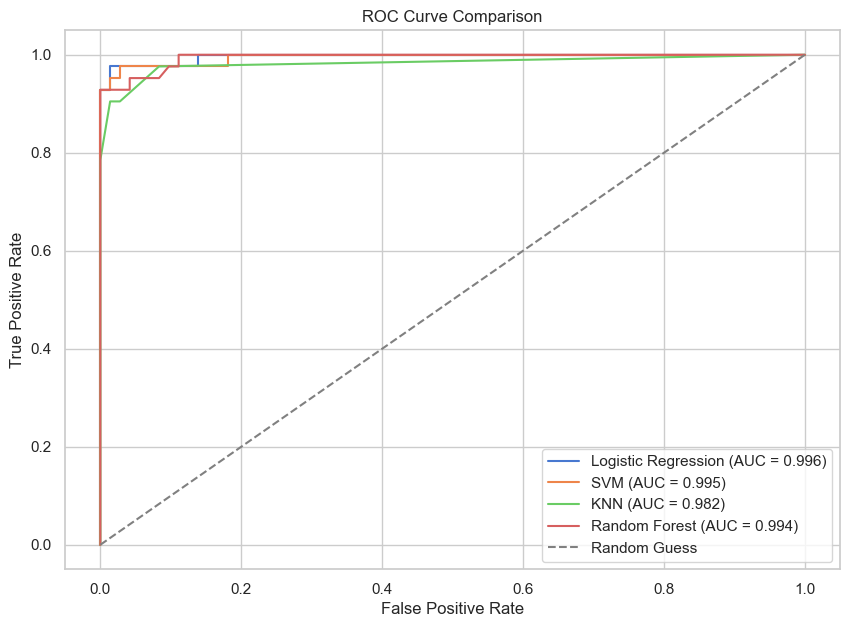

In [28]:
# ROC Curves for All Models
# Predicted probabilities for the positive class (malignant = 1)
# For models trained on scaled features, we use X_test_scaled

log_prob = log_model.predict_proba(X_test_scaled)[:, 1]   # Probability of class 1 for Logistic Regression
svm_prob = svm_model.predict_proba(X_test_scaled)[:, 1]   # Probability of class 1 for SVM
knn_prob = knn_model.predict_proba(X_test_scaled)[:, 1]   # Probability of class 1 for KNN

# Random Forest is trained on the original (unscaled) features
rf_prob = rf_model.predict_proba(X_test)[:, 1]            # Probability of class 1 for Random Forest


plt.figure(figsize=(10, 7))

# Loop through each model and plot its ROC curve
for name, probs in [
    ("Logistic Regression", log_prob),
    ("SVM", svm_prob),
    ("KNN", knn_prob),
    ("Random Forest", rf_prob)
]:
    # Compute False Positive Rate (fpr) and True Positive Rate (tpr) at different classification thresholds
    fpr, tpr, _ = roc_curve(y_test, probs)

    # Compute the Area Under the Curve (AUC) for the current model
    model_auc = auc(fpr, tpr)

    # Plot the ROC curve with the model name and its AUC in the legend
    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {model_auc:.3f})"
    )

# Plot the diagonal reference line (random classifier)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Guess"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

# Show the legend (model names + AUC scores)
plt.legend()

plt.show()


### How to read the ROC curve 


- The x-axis (False Positive Rate) shows how often the model raises a false alarm.
- The y-axis (True Positive Rate) shows how often the model correctly detects the positive class (malignant tumors).
- A good model has a curve that goes up quickly and stays close to the top-left corner.
- The closer the curve is to the top-left and the higher the AUC, the better the model is at distinguishing malignant from benign cases.

### ROC Curve Analysis

- The ROC curve shows how well each model separates the two classes by comparing the True Positive Rate and False Positive Rate at different thresholds.
- Logistic Regression and SVM achieved the highest AUC (0.995), showing excellent classification performance.
- Random Forest also performed very well with an AUC of 0.993.
- KNN had a slightly lower AUC (0.979), indicating weaker performance compared to the other models.
Overall, Logistic Regression and SVM performed best based on the ROC‑AUC metric.

---

## 13. Best Model Selection

- After comparing all models using classification metrics, confusion matrices, and ROC curves, Logistic Regression and SVM achieved the best overall performance on the dataset.

- Both models produced the highest accuracy and F1-scores while also achieving excellent ROC-AUC values, indicating strong classification capability.

- Random Forest also performed well and provided useful feature importance analysis, although its overall performance was slightly lower.
- KNN showed comparatively lower performance than the other models.

Overall, Logistic Regression and SVM were selected as the most reliable models for this classification task.

---

## 14. Model Interpretation

### 14.1 Feature Importance (Random Forest)

Although Random Forest is not the top-performing model, it provides useful feature importance scores that help interpret the contribution of different features.

In [29]:
# Extract feature importance scores from the trained Random Forest model
importances = rf_model.feature_importances_

# Create a DataFrame linking features with their importance scores
feat_imp = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importances
})

# Sort features by importance
feat_imp = feat_imp.sort_values(by="Importance", ascending=False)


feat_imp = feat_imp.head(10)    # Top Features


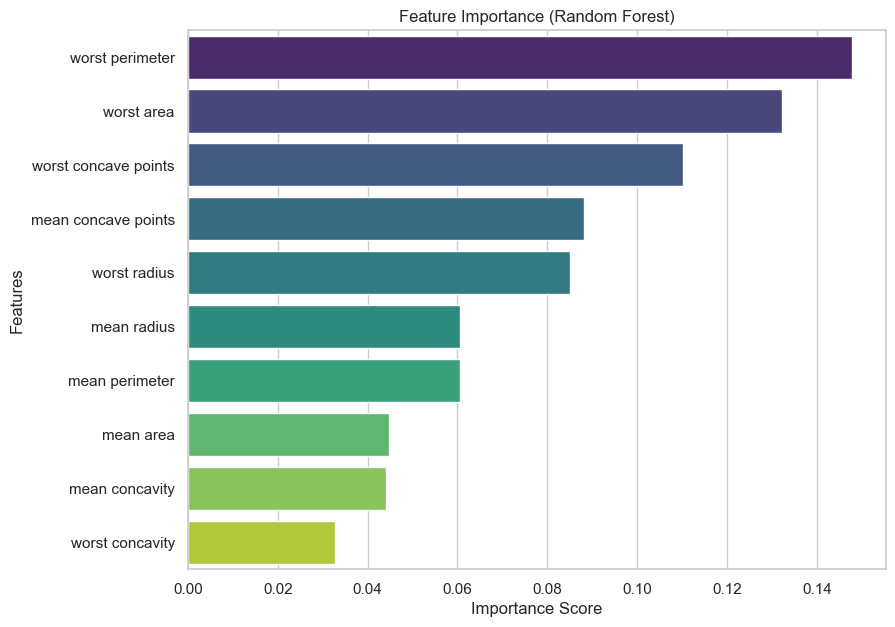

In [30]:
plt.figure(figsize=(9, 7))

sns.barplot(
    data=feat_imp,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()


### Feature Importance Interpretation
- The chart shows which features the Random Forest model relied on most when making predictions.
- The most important features include worst perimeter, worst area, and mean concave points.
- These features describe the size and shape of the tumor, suggesting that tumor geometry plays a key role in distinguishing between malignant and benign cases.
- Feature importance is shown for the Random Forest model because tree‑based models naturally compute importance scores during training.

---

### 14.2 SHAP Analysis

SHAP explainer for Logistic Regression

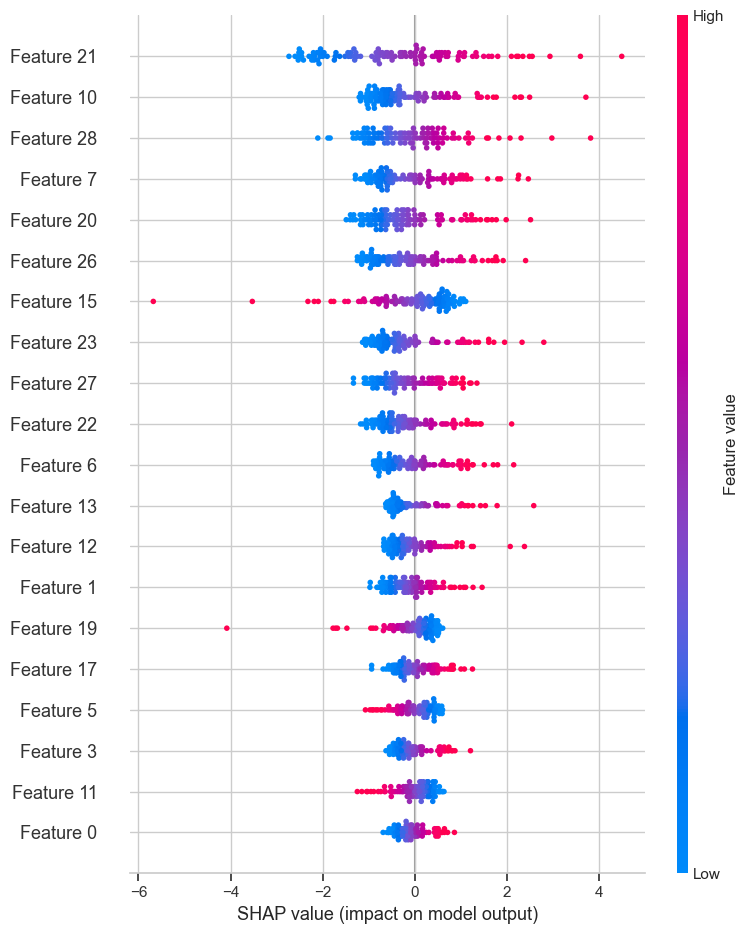

In [31]:
# Create SHAP explainer for Logistic Regression
explainer = shap.Explainer(log_model, X_train_scaled)

# Calculate SHAP values
shap_values = explainer(X_test_scaled)

# Summary plot showing feature impact
shap.summary_plot(shap_values, X_test_scaled)


### SHAP Interpretation (Logistic Regression)
- Both Logistic Regression and SVM achieved very similar performance in the evaluation phase. In this section, Logistic Regression is selected for SHAP interpretation because it is a simpler and more interpretable model.
- SHAP analysis helps explain how individual features influence the model’s predictions.
- The summary plot below shows the contribution of each feature to the classification outcome.
- The dataset contains 30 numerical features describing characteristics of cell nuclei. Some features appear as indexed variables, but they represent measurements related to tumor size, texture, and shape.
- The SHAP results show that several features have a strong impact on the model’s predictions, indicating that geometric and structural properties of the tumor play a key role in distinguishing malignant from benign tumors.

---

Bar plot of global feature importance

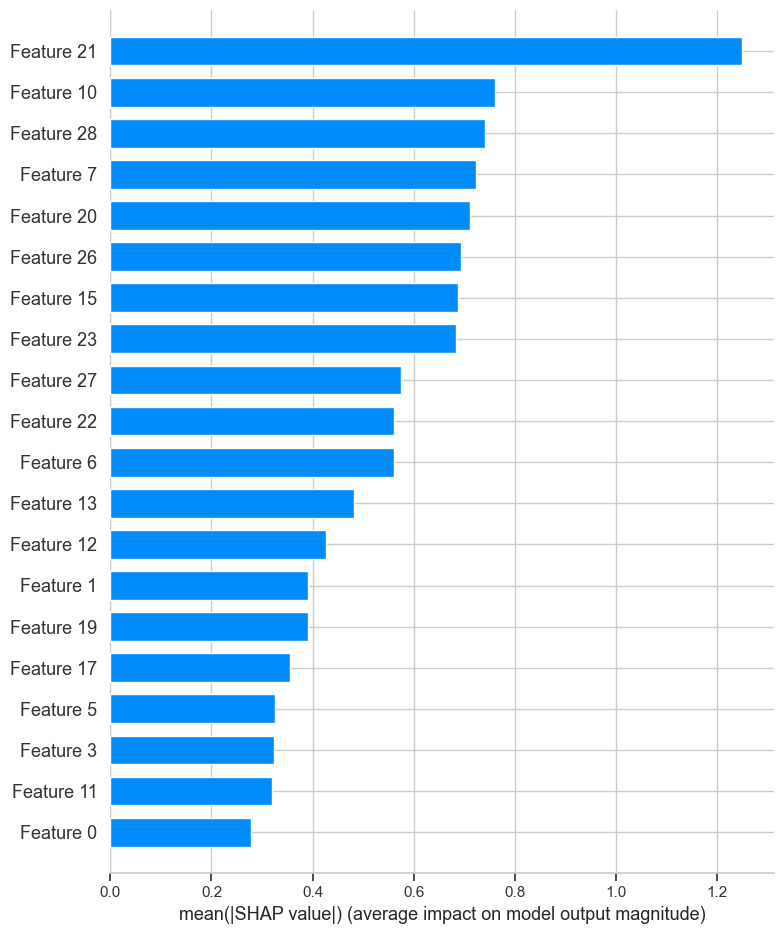

In [32]:
# Bar plot of global feature importance
shap.summary_plot(shap_values, X_test_scaled, plot_type="bar")


## 15. Summary of Results
- In this project, multiple machine learning models were trained to classify breast tumors as malignant or benign using the Wisconsin Breast Cancer dataset.
- The models were evaluated using several performance metrics including accuracy, precision, recall, F1-score, and ROC-AUC.
- The results showed that Logistic Regression and SVM achieved the best overall performance.
- Both models demonstrated strong predictive ability and balanced evaluation metrics, indicating that they can effectively distinguish between malignant and benign tumors.
---

## 16. Medical Interpretation
- The interpretation results indicate that features related to tumor size, perimeter, and concave points have the strongest influence on model predictions. These characteristics describe the geometric structure of the tumor cells.
- This observation aligns with medical knowledge, as malignant tumors often show irregular shapes, larger sizes, and more complex boundaries compared to benign tumors.

---

## 17. Limitations
- Although the models achieved strong performance, this study has several limitations.
- The dataset used in this project is relatively small and originates from a single source. In real-world medical settings, datasets are often larger and more diverse.
- Additionally, the models were trained on structured numerical features rather than raw medical images, which limits the scope of the analysis.

---

## 18. Future Work
- Future work could explore the use of larger and more diverse medical datasets to improve model generalization.
- Deep learning approaches applied to medical imaging data may also provide additional insights.
- Furthermore, advanced model interpretation techniques could be used to better understand the decision-making process of complex machine learning models in medical diagnosis tasks.
---

### References
Scikit-learn Developers. Breast Cancer Wisconsin Dataset.
https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html

Scikit-learn Documentation. Machine Learning in Python.
https://scikit-learn.org

SHAP Documentation. SHAP (SHapley Additive Explanations).
https://shap.readthedocs.io

Matplotlib Documentation. Visualization with Python.
https://matplotlib.org

Seaborn Documentation. Statistical Data Visualization in Python.
https://seaborn.pydata.org


---

By : Sahel Sepehri
- github.com/sahelsepehri
- sahelsepehri99@gmail.com